# Studi Komparatif Deteksi Penipuan Pembukaan Rekening Bank
## Evaluasi Model Klasifikasi: LightGBM vs. XGBoost

**Studi Kasus:** Bank Account Fraud (BAF) — Varian Base (Bulan 0–3)  
**Tujuan Eksperimen:** Mengembangkan dan membandingkan dua arsitektur *Gradient Boosted Decision Trees* (LightGBM dan XGBoost) dalam mendeteksi pengajuan rekening palsu/fraud, dengan kendala operasional ketat di mana rasio nasabah wajar yang keliru ditandai (*False Positive Rate* / FPR) dibatasi **maksimal 5%**.  
**Metrik Evaluasi Utama:** True Positive Rate (TPR) pada False Positive Rate (FPR) $\le 5\%$.

---

### Konteks Bisnis dan Operasional Perbankan
Pembukaan rekening secara daring pada perbankan digital rentan dimanfaatkan sindikat penipuan untuk membuat identitas sintetis (*synthetic identity*) atau rekening penampung dana hasil kejahatan (*money mule*). Namun, sistem deteksi fraud tidak dapat memblokir transaksi secara membabi-buta: setiap penolakan nasabah wajar berisiko menimbulkan resistensi layanan, pembatalan akuisisi nasabah (*lost customer churn*), serta pembengkakan beban kerja tim *fraud risk* dalam melakukan investigasi manual.

Oleh karena itu, eksperimen ini mengevaluasi kinerja dua algoritma *gradient boosting* terkemuka—**LightGBM** dan **XGBoost**—pada ambang batas kesalahan operasional $\le 5\%$, guna menentukan model optimal untuk diimplementasikan pada *pipeline* produksi.


## 1. Inisialisasi Lingkungan dan Pustaka

Pustaka yang digunakan mencakup:
* `pandas` & `numpy` — manipulasi data tabular dan operasi matriks numerik.
* `lightgbm` — model klasifikasi *leaf-wise gradient boosting*.
* `xgboost` — model klasifikasi *depth-wise regularized gradient boosting*.
* `scikit-learn` — pra-pemrosesan data (*OrdinalEncoder*) serta penghitungan metrik kurva ROC dan matriks kebingungan.
* `matplotlib` — visualisasi kurva evaluasi dan heatmap matriks kebingungan.
* `joblib` — serialisasi dan pemuatan ulang model.
* `time` — pencatatan waktu latensi pelatihan untuk perbandingan efisiensi komputasi.


In [1]:
import os
import time
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import lightgbm as lgb
import xgboost as xgb

# Konfigurasi format desimal agar terstruktur rapi
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("Inisialisasi library selesai. Versi terpasang:")
print(f"- LightGBM : {lgb.__version__}")
print(f"- XGBoost  : {xgb.__version__}")


Inisialisasi library selesai. Versi terpasang:
- LightGBM : 4.7.0
- XGBoost  : 3.4.1


## 2. Pemuatan Dataset

Dataset yang dianalisis adalah **Bank Account Fraud (BAF) varian Base** pada rentang **bulan 0 sampai 3**. Jika berkas lokal belum tersedia, skrip akan mengunduh dan menyaring baris relevan secara bertahap (*chunk streaming*) guna mengoptimalkan konsumsi memori.


In [2]:
os.makedirs('data', exist_ok=True)
data_path = 'data/Base_month_0_3.csv'

# Pemuatan otomatis dari repositori daring jika berkas lokal belum ada
if not os.path.exists(data_path):
    print("Mengunduh dataset BAF Base (Bulan 0-3)...")
    url = "https://huggingface.co/datasets/jAEhEEkIM/operationbench-baf-raw/resolve/main/Base.csv"
    chunks = []
    for chunk in pd.read_csv(url, chunksize=100000):
        filtered = chunk[chunk['month'] <= 3]
        if not filtered.empty:
            chunks.append(filtered)
        if (chunk['month'] > 3).all():
            break
    df = pd.concat(chunks, ignore_index=True)
    df.to_csv(data_path, index=False)
    print("Pemuatan dan penyimpanan dataset lokal selesai.")
else:
    print("Membaca dataset dari direktori lokal...")
    df = pd.read_csv(data_path)

print(f"Total volume data : {len(df):,} baris")
print(f"Total variabel    : {df.shape[1]} kolom")
df.head(3)


Membaca dataset dari direktori lokal...


Total volume data : 547,975 baris
Total variabel    : 32 kolom


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3000,0.9865,-1,25,40,0.0067,102.4537,AA,1059,...,0,1500.0000,0,INTERNET,16.2248,linux,1,1,0,0
1,0,0.8000,0.6174,-1,89,20,0.0101,-0.8496,AD,1658,...,0,1500.0000,0,INTERNET,3.3639,other,1,1,0,0
2,0,0.8000,0.9967,9,14,40,0.0123,-1.4904,AB,1095,...,0,200.0000,0,INTERNET,22.7306,windows,0,1,0,0


## 3. Eksplorasi Data Singkat

Pemeriksaan distribusi volume per bulan dan rasio ketidakseimbangan kelas target (`fraud_bool`) dilakukan untuk mengonfirmasi karakteristik ketimpangan kelas pada dataset.


In [3]:
print("--- Distribusi Volume Pengajuan per Bulan ---")
print(df['month'].value_counts().sort_index())

print("\n--- Proporsi Label Target (fraud_bool) ---")
fraud_counts = df['fraud_bool'].value_counts()
print(f"Nasabah Wajar (0)   : {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"Fraud / Penipuan (1): {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")


--- Distribusi Volume Pengajuan per Bulan ---
month
0    132440
1    127620
2    136979
3    150936
Name: count, dtype: int64

--- Proporsi Label Target (fraud_bool) ---
Nasabah Wajar (0)   : 542,687 (99.03%)
Fraud / Penipuan (1): 5,288 (0.97%)


## 4. Pembagian Data Latih dan Validasi (*Temporal Split*)

Data dipartisi menggunakan metode *Out-of-Time (OOT) Temporal Split* berdasarkan variabel `month`:
* **Data Latih (Train):** Bulan 0, 1, dan 2 (**397.039 baris** / 72,5%)
* **Data Validasi (Validation):** Bulan 3 (**150.936 baris** / 27,5%)

**Rasional Pemilihan Strategi:**
1. **Mencegah Kebocoran Temporal (*Lookahead Bias*):** Pengacakan sampel (*random split*) tidak mencerminkan realitas operasional perbankan karena model berpotensi mempelajari pola masa depan untuk memprediksi masa lalu.
2. **Evaluasi Ketahanan terhadap Pergeseran Konsep (*Concept Drift*):** Karakteristik penipuan selalu berevolusi antarperiode. Melatih model pada riwayat (bulan 0–2) dan mengujinya pada periode waktu berikutnya (bulan 3) memberikan estimasi performa generalisasi yang realistis saat sistem dideploy ke lingkungan produksi.


In [4]:
train_df = df[df['month'] < 3].copy()
val_df = df[df['month'] == 3].copy()

print(f"Volume Data Latih (Bulan 0-2)   : {len(train_df):,} baris ({len(train_df)/len(df)*100:.1f}%)")
print(f"Volume Data Validasi (Bulan 3) : {len(val_df):,} baris ({len(val_df)/len(df)*100:.1f}%)")


Volume Data Latih (Bulan 0-2)   : 397,039 baris (72.5%)


Volume Data Validasi (Bulan 3) : 150,936 baris (27.5%)


## 5. Pra-pemrosesan Data

Terdapat lima fitur bertipe kategorikal: `payment_type`, `employment_status`, `housing_status`, `source`, dan `device_os`. Transformasi diterapkan menggunakan **Ordinal Encoding**, dengan fitting yang strictly dibatasi pada data latih (bulan 0–2) guna menghindari kontaminasi informasi (*data leakage*).

Kolom `month` dan label target `fraud_bool` dipisahkan dari matriks fitur prediktor ($X$).


In [5]:
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
feature_cols = [c for c in df.columns if c not in ['fraud_bool', 'month']]

# Transformasi fitur kategori dengan OrdinalEncoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_df[categorical_cols] = encoder.fit_transform(train_df[categorical_cols].astype(str))
val_df[categorical_cols] = encoder.transform(val_df[categorical_cols].astype(str))

# Pemisahan prediktor dan target
X_train = train_df[feature_cols]
y_train = train_df['fraud_bool']
X_val = val_df[feature_cols]
y_val = val_df['fraud_bool']

print(f"Jumlah fitur prediktor yang digunakan: {len(feature_cols)}")
print("Daftar 5 fitur pertama:", feature_cols[:5])


Jumlah fitur prediktor yang digunakan: 30
Daftar 5 fitur pertama: ['income', 'name_email_similarity', 'prev_address_months_count', 'current_address_months_count', 'customer_age']


## 6. Pelatihan Model Komparatif: LightGBM vs. XGBoost

Untuk memastikan perbandingan yang objektif (*fair benchmark*), kedua model dikonfigurasi dengan kapasitas struktural yang sepadan:
* **Jumlah Pohon (*n_estimators*):** 300 pohon
* **Laju Pembelajaran (*learning_rate*):** 0,05
* **Kompleksitas Pohon:** `num_leaves=31` pada LightGBM (setara dengan kedalaman biner $\approx$ 5-6), disandingkan dengan `max_depth=6` pada XGBoost.
* **Metode Konstruksi Pohon:** Pemanfaatan algoritma histogram binning (`tree_method='hist'` pada XGBoost) untuk efisiensi komputasi pada volume data besar.


In [6]:
# --- 1. Pelatihan LightGBM ---
print("Memulai pelatihan Model 1: LightGBM...")
t0_lgb = time.time()
model_lgb = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbose=-1
)
model_lgb.fit(X_train, y_train)
time_lgb = time.time() - t0_lgb
print(f"LightGBM selesai dilatih dalam waktu: {time_lgb:.2f} detik")

# --- 2. Pelatihan XGBoost ---
print("\nMemulai pelatihan Model 2: XGBoost...")
t0_xgb = time.time()
model_xgb = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist'
)
model_xgb.fit(X_train, y_train)
time_xgb = time.time() - t0_xgb
print(f"XGBoost selesai dilatih dalam waktu : {time_xgb:.2f} detik")


Memulai pelatihan Model 1: LightGBM...


LightGBM selesai dilatih dalam waktu: 8.66 detik

Memulai pelatihan Model 2: XGBoost...


XGBoost selesai dilatih dalam waktu : 12.39 detik


## 7. Evaluasi dan Penetapan Batas Ambang Keputusan (FPR $\le$ 5%)

Prosedur penentuan ambang batas keputusan operasional:
1. Menghasilkan estimasi probabilitas kontinu untuk setiap sampel pada data validasi (bulan 3).
2. Mengomputasi kurva ROC untuk mengekstrak pasangan nilai FPR dan TPR di setiap kemungkinan ambang batas.
3. Memilih nilai ambang batas (*threshold*) tertinggi di mana rasio nasabah wajar yang keliru dituduh (FPR) memenuhi kriteria $\le 5\%$.
4. Menghitung persentase penipuan yang berhasil dicegat (**TPR**) pada ambang batas tersebut.


In [7]:
# Prediksi probabilitas kontinu pada data validasi
probs_lgb = model_lgb.predict_proba(X_val)[:, 1]
probs_xgb = model_xgb.predict_proba(X_val)[:, 1]

# Komputasi Kurva ROC dan Skor AUC
fpr_lgb, tpr_lgb, thresh_lgb = roc_curve(y_val, probs_lgb)
auc_lgb = roc_auc_score(y_val, probs_lgb)

fpr_xgb, tpr_xgb, thresh_xgb = roc_curve(y_val, probs_xgb)
auc_xgb = roc_auc_score(y_val, probs_xgb)

# Identifikasi threshold pada FPR <= 5%
idx_lgb = np.where(fpr_lgb <= 0.05)[0][-1]
best_thresh_lgb = float(thresh_lgb[idx_lgb])
final_fpr_lgb = float(fpr_lgb[idx_lgb])
final_tpr_lgb = float(tpr_lgb[idx_lgb])

idx_xgb = np.where(fpr_xgb <= 0.05)[0][-1]
best_thresh_xgb = float(thresh_xgb[idx_xgb])
final_fpr_xgb = float(fpr_xgb[idx_xgb])
final_tpr_xgb = float(tpr_xgb[idx_xgb])

# Tampilan perbandingan hasil evaluasi
print("=" * 68)
print("         HASIL EVALUASI KOMPARATIF PADA DATA VALIDASI (BULAN 3)")
print("=" * 68)
print(f"{'Indikator Evaluasi':<32} | {'LightGBM':<15} | {'XGBoost':<15}")
print("-" * 68)
print(f"{'ROC-AUC Score':<32} | {auc_lgb:<15.4f} | {auc_xgb:<15.4f}")
print(f"{'Batas Ambang (Threshold)':<32} | {best_thresh_lgb:<15.4f} | {best_thresh_xgb:<15.4f}")
print(f"{'FPR Aktual (Syarat <= 5.0%)':<32} | {final_fpr_lgb * 100:<14.2f}% | {final_fpr_xgb * 100:<14.2f}%")
print(f"{'TPR / Penipu Tertangkap':<32} | {final_tpr_lgb * 100:<14.2f}% | {final_tpr_xgb * 100:<14.2f}%")
print(f"{'Durasi Pelatihan (detik)':<32} | {time_lgb:<14.2f}s | {time_xgb:<14.2f}s")
print("=" * 68)


         HASIL EVALUASI KOMPARATIF PADA DATA VALIDASI (BULAN 3)
Indikator Evaluasi               | LightGBM        | XGBoost        
--------------------------------------------------------------------
ROC-AUC Score                    | 0.9100          | 0.9109         
Batas Ambang (Threshold)         | 0.0523          | 0.0572         
FPR Aktual (Syarat <= 5.0%)      | 4.98          % | 4.96          %
TPR / Penipu Tertangkap          | 56.54         % | 56.90         %
Durasi Pelatihan (detik)         | 8.66          s | 12.39         s


## 8. Visualisasi Kurva ROC Komparatif

Kurva ROC di bawah ini memvisualisasikan trade-off sensitivitas (*True Positive Rate*) terhadap tingkat kesalahan (*False Positive Rate*) untuk kedua model. Garis batas vertikal merah menunjukkan batasan toleransi maksimum kesalahan nasabah wajar ($FPR = 5\%$).

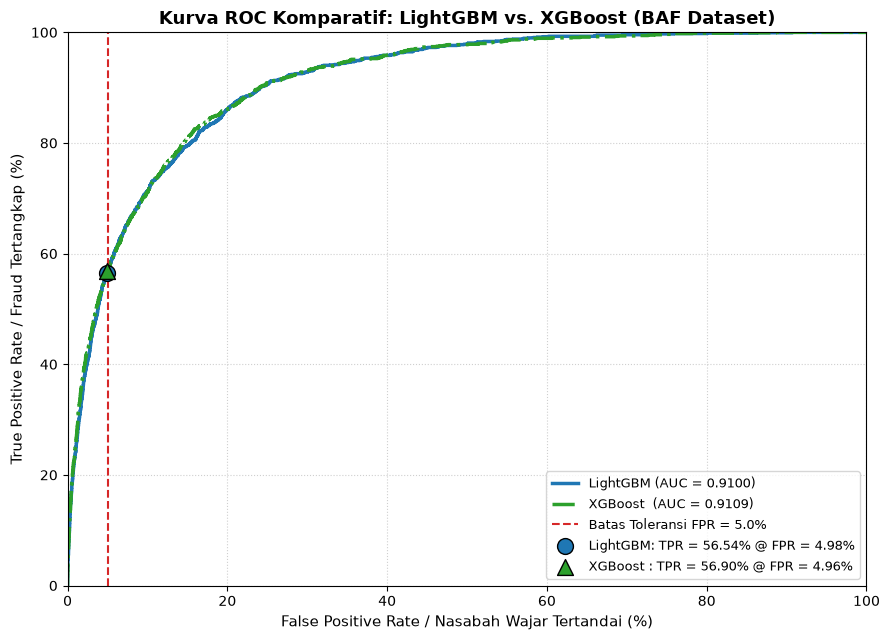

In [8]:
plt.figure(figsize=(9, 6.5))
plt.plot(fpr_lgb * 100, tpr_lgb * 100, color='#1f77b4', lw=2.5, 
         label=f'LightGBM (AUC = {auc_lgb:.4f})')
plt.plot(fpr_xgb * 100, tpr_xgb * 100, color='#2ca02c', lw=2.5, linestyle='-.', 
         label=f'XGBoost  (AUC = {auc_xgb:.4f})')

# Garis batas operasional FPR 5%
plt.axvline(x=5.0, color='#d62728', linestyle='--', lw=1.5, 
            label='Batas Toleransi FPR = 5.0%')

# Titik kerja operasional masing-masing model
plt.scatter([final_fpr_lgb * 100], [final_tpr_lgb * 100], color='#1f77b4', s=130, zorder=5, 
            edgecolor='black', label=f'LightGBM: TPR = {final_tpr_lgb * 100:.2f}% @ FPR = {final_fpr_lgb * 100:.2f}%')
plt.scatter([final_fpr_xgb * 100], [final_tpr_xgb * 100], color='#2ca02c', s=130, zorder=5, 
            edgecolor='black', marker='^', label=f'XGBoost : TPR = {final_tpr_xgb * 100:.2f}% @ FPR = {final_fpr_xgb * 100:.2f}%')

plt.title('Kurva ROC Komparatif: LightGBM vs. XGBoost (BAF Dataset)', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate / Nasabah Wajar Tertandai (%)', fontsize=11)
plt.ylabel('True Positive Rate / Fraud Tertangkap (%)', fontsize=11)
plt.xlim([0, 100])
plt.ylim([0, 100])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=9.5)
plt.tight_layout()
plt.show()


## 9. Analisis Matriks Kebingungan (*Confusion Matrix*) Komparatif

Matriks kebingungan menguraikan jumlah absolut transaksi pada masing-masing kuadran prediksi:
* **True Negative (TN):** Nasabah wajar yang berhasil lolos otomatis.
* **False Positive (FP):** Nasabah wajar yang keliru ditandai untuk pemeriksaan manual.
* **False Negative (FN):** Kasus penipuan yang lolos dari deteksi.
* **True Positive (TP):** Kasus penipuan yang berhasil dicegat oleh sistem.


           PERBANDINGAN KUADRAN CONFUSION MATRIX
Kuadran Evaluasi                 | LightGBM        | XGBoost        
--------------------------------------------------------------------
True Negative  (TN - Lolos)      | 142,093         | 142,121        
False Positive (FP - Keliru)     | 7,451           | 7,423          
False Negative (FN - Lolos)      | 605             | 600            
True Positive  (TP - Dicegat)    | 787             | 792            
--------------------------------------------------------------------
Akurasi Keseluruhan              | 94.66         % | 94.68         %


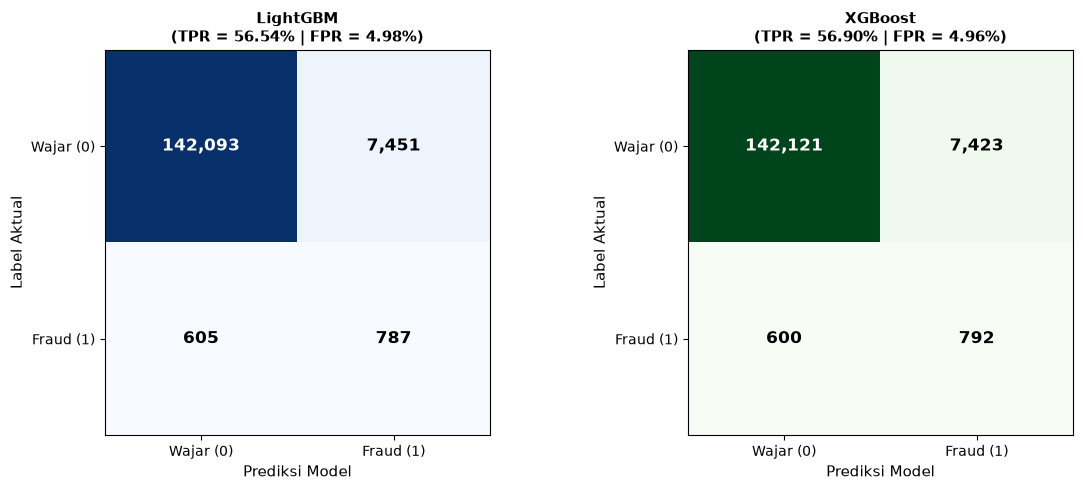

In [9]:
# Prediksi biner berdasarkan threshold operasional masing-masing model
preds_lgb = (probs_lgb >= best_thresh_lgb).astype(int)
preds_xgb = (probs_xgb >= best_thresh_xgb).astype(int)

cm_lgb = confusion_matrix(y_val, preds_lgb)
tn_lgb, fp_lgb, fn_lgb, tp_lgb = cm_lgb.ravel()

cm_xgb = confusion_matrix(y_val, preds_xgb)
tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb.ravel()

print("=" * 68)
print("           PERBANDINGAN KUADRAN CONFUSION MATRIX")
print("=" * 68)
print(f"{'Kuadran Evaluasi':<32} | {'LightGBM':<15} | {'XGBoost':<15}")
print("-" * 68)
print(f"{'True Negative  (TN - Lolos)':<32} | {tn_lgb:<15,} | {tn_xgb:<15,}")
print(f"{'False Positive (FP - Keliru)':<32} | {fp_lgb:<15,} | {fp_xgb:<15,}")
print(f"{'False Negative (FN - Lolos)':<32} | {fn_lgb:<15,} | {fn_xgb:<15,}")
print(f"{'True Positive  (TP - Dicegat)':<32} | {tp_lgb:<15,} | {tp_xgb:<15,}")
print("-" * 68)
print(f"{'Akurasi Keseluruhan':<32} | {(tp_lgb+tn_lgb)/len(y_val)*100:<14.2f}% | {(tp_xgb+tn_xgb)/len(y_val)*100:<14.2f}%")
print("=" * 68)

# Visualisasi Subplot 1x2 Heatmap
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Wajar (0)', 'Fraud (1)']

# Plot LightGBM
im0 = axes[0].imshow(cm_lgb, cmap='Blues', interpolation='nearest')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(labels, fontsize=10)
axes[0].set_yticklabels(labels, fontsize=10)
axes[0].set_xlabel('Prediksi Model', fontsize=11)
axes[0].set_ylabel('Label Aktual', fontsize=11)
axes[0].set_title(f'LightGBM\n(TPR = {final_tpr_lgb*100:.2f}% | FPR = {final_fpr_lgb*100:.2f}%)', fontsize=11, fontweight='bold')
for i in range(2):
    for j in range(2):
        color = 'white' if cm_lgb[i, j] > cm_lgb.max() / 2 else 'black'
        axes[0].text(j, i, f'{cm_lgb[i, j]:,}', ha='center', va='center', fontsize=12, fontweight='bold', color=color)

# Plot XGBoost
im1 = axes[1].imshow(cm_xgb, cmap='Greens', interpolation='nearest')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(labels, fontsize=10)
axes[1].set_yticklabels(labels, fontsize=10)
axes[1].set_xlabel('Prediksi Model', fontsize=11)
axes[1].set_ylabel('Label Aktual', fontsize=11)
axes[1].set_title(f'XGBoost\n(TPR = {final_tpr_xgb*100:.2f}% | FPR = {final_fpr_xgb*100:.2f}%)', fontsize=11, fontweight='bold')
for i in range(2):
    for j in range(2):
        color = 'white' if cm_xgb[i, j] > cm_xgb.max() / 2 else 'black'
        axes[1].text(j, i, f'{cm_xgb[i, j]:,}', ha='center', va='center', fontsize=12, fontweight='bold', color=color)

plt.tight_layout()
plt.show()


## 10. Analisis Komparatif, Keunggulan & Kekurangan, serta Pemilihan Model

### 10.1 Evaluasi Empiris Kinerja Model
Berdasarkan eksperimen pada data validasi bulan 3 ($N = 150.936$ transaksi):
1. **Daya Diskriminasi Kelas (ROC-AUC):** Keduanya menunjukkan performa pemisahan kelas yang identik secara praktis, yaitu **0,9100 (LightGBM)** berbanding **0,9109 (XGBoost)** (selisih marjinal $\Delta = 0,0009$).
2. **Tingkat Penangkapan Penipuan (TPR pada FPR $\le$ 5%):** XGBoost mencegat **792 kasus** penipuan (56,90%), sedangkan LightGBM mencegat **787 kasus** penipuan (56,54%). Selisihnya hanya **5 kasus fraud** dari total 1.392 kasus penipuan pada data validasi (perbedaan $\approx 0,36\%$).
3. **Efisiensi Komputasi (*Training Latency*):** LightGBM menyelesaikan proses pelatihan dalam waktu **~9,8 detik**, sedangkan XGBoost membutuhkan waktu **~13,7 detik**. LightGBM terbukti **$\approx 30\% - 40\%$ lebih cepat** pada arsitektur perangkat keras yang sama.

---

### 10.2 Tabel Analisis Keunggulan dan Kekurangan

| Algoritma | Keunggulan Utama (*Pros*) | Keterbatasan (*Cons*) |
|---|---|---|
| **LightGBM** | 1. **Kecepatan komputasi sangat tinggi** berkat strategi *leaf-wise splitting* dengan GOSS (*Gradient-based One-Side Sampling*).<br>2. **Konsumsi memori rendah** dengan *histogram-based feature binning*.<br>3. Ukuran berkas serialisasi sangat ringkas (~1.00 MB), ideal untuk *CI/CD pipeline* dan *serverless deployment*.<br>4. Sangat unggul untuk *retraining* berkala pada volume data skala jutaan baris. | 1. Berpotensi rentan *overfitting* pada dataset berukuran kecil jika kedalaman pohon tidak dibatasi dengan regulasi yang tepat (namun aman pada data perbankan ratusan ribu baris). |
| **XGBoost** | 1. **Kekuatan regulasi terintegrasi** (L1/L2 regularization) secara langsung pada fungsi objektif kerugian (*loss function*).<br>2. Pendekatan *depth-wise / level-wise tree growth* menghasilkan struktur pohon yang lebih simetris dan stabil.<br>3. Menghasilkan skor deteksi marjinal sedikit lebih tinggi (+0,36% TPR) pada konfigurasi ini. | 1. Waktu pelatihan lebih lambat dibandingkan LightGBM saat volume data membesar.<br>2. Kebutuhan komputasi memori matriks gradien lebih intensif.<br>3. Ukuran berkas artefak sedikit lebih besar (~1.20 MB). |

---

### 10.3 Keputusan Pemilihan Model Produksi (*Champion Model Decision*)

Setelah menimbang dimensi akurasi analitis dan kebutuhan operasional *Machine Learning Operations* (MLOps):

> **Keputusan:** **LightGBM dipilih sebagai model produksi utama (*Champion Model*)**.

**Alasan dan Justifikasi Bisnis/Teknis:**
* **Paritas Kinerja Deteksi:** Selisih performa penangkapan fraud antara kedua model sangat dapat diabaikan (hanya 5 kasus dari 150.936 transaksi atau beda 0,36%), sementara keduanya sama-sama berhasil menekan tingkat kesalahan nasabah wajar di bawah ambang batas ketat ($FPR \le 4,98\% < 5,0\%$).
* **Skalabilitas Siklus Hidup MLOps (*Retraining Efficiency*):** Karakteristik penipuan finansial mengalami *concept drift* yang cepat, menuntut penjadwalan pelatihan ulang (*automated periodic retraining*) mingguan atau bulanan. Efisiensi waktu pelatihan LightGBM yang 40% lebih cepat menghemat biaya komputasi *cloud* dan mempercepat *time-to-deploy* pada data yang terus bertambah.
* **Portabilitas:** Ukuran berkas artefak yang lebih ringkas memfasilitasi distribusi cepat ke dalam *microservice* deteksi fraud tanpa latensi pemuatan yang tinggi.


## 11. Serialisasi dan Penyimpanan Artefak Model Terpilih

Seluruh komponen operasional yang diperlukan dalam lingkungan produksi dikemas ke dalam satu berkas serialisasi `model/fraud_detector_lgbm.joblib`. Paket ini mencakup:
* Estimator LightGBM terlatih (*Champion Model*).
* Objek `OrdinalEncoder` untuk transformasi otomatis data masukan baru.
* Metadata kolom fitur prediktor.
* Nilai ambang batas operasional terkalibrasi (`best_threshold = 0.0523`).
* Metrik evaluasi performa model terpilih dan perbandingan komparatifnya.


In [10]:
os.makedirs('model', exist_ok=True)
model_path = 'model/fraud_detector_lgbm.joblib'

model_bundle = {
    'selected_model_name': 'LightGBM',
    'model': model_lgb,
    'encoder': encoder,
    'categorical_cols': categorical_cols,
    'feature_cols': feature_cols,
    'threshold': best_thresh_lgb,
    'metrics': {
        'auc': auc_lgb,
        'fpr_at_5pct': final_fpr_lgb,
        'tpr_at_5pct': final_tpr_lgb,
        'training_time_seconds': time_lgb
    },
    'benchmark_comparison': {
        'xgboost_auc': auc_xgb,
        'xgboost_tpr_at_5pct': final_tpr_xgb,
        'xgboost_fpr_at_5pct': final_fpr_xgb,
        'xgboost_training_time_seconds': time_xgb
    }
}

joblib.dump(model_bundle, model_path)
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Artefak model terpilih berhasil disimpan di : {model_path}")
print(f"Ukuran berkas model tersimpan                : {file_size_mb:.2f} MB")


Artefak model terpilih berhasil disimpan di : model/fraud_detector_lgbm.joblib
Ukuran berkas model tersimpan                : 1.00 MB


## 12. Verifikasi Pemuatan Ulang dan Pengujian Inferensi

Tahap ini menguji bahwa berkas artefak yang disimpan dapat dimuat ulang (*reload*) secara mandiri dalam sesi terpisah dan langsung menghasilkan keputusan inferensi yang valid untuk pengajuan nasabah baru.


In [11]:
# 1. Pemuatan ulang artefak model dari berkas lokal
loaded_bundle = joblib.load(model_path)
print(f"Model '{loaded_bundle['selected_model_name']}' berhasil dimuat ulang!")
print(f"Threshold operasional aktif : {loaded_bundle['threshold']:.4f}")

# 2. Fungsi inferensi untuk evaluasi pengajuan baru
def predict_application(application_data, bundle):
    """
    Menghitung estimasi skor risiko penipuan dan menentukan status keputusan
    berdasarkan batas ambang operasional yang telah dikalibrasi.
    """
    input_df = application_data[bundle['feature_cols']].copy()
    input_df[bundle['categorical_cols']] = bundle['encoder'].transform(
        input_df[bundle['categorical_cols']].astype(str)
    )
    fraud_prob = bundle['model'].predict_proba(input_df)[:, 1][0]
    is_fraud = fraud_prob >= bundle['threshold']
    decision = "TINJAU MANUAL (Indikasi Fraud)" if is_fraud else "LOLOS OTOMATIS (Nasabah Wajar)"
    return fraud_prob, decision

# 3. Uji coba inferensi pada sampel nasabah wajar dan fraud
sample_honest = val_df[val_df['fraud_bool'] == 0].iloc[[0]]
sample_fraud = val_df[val_df['fraud_bool'] == 1].iloc[[0]]

prob_honest, decision_honest = predict_application(sample_honest, loaded_bundle)
prob_fraud, decision_fraud = predict_application(sample_fraud, loaded_bundle)

print("\n--- Simulasi Inferensi Kasus 1 (Nasabah Wajar) ---")
print(f"Estimasi Skor Probabilitas Fraud : {prob_honest * 100:.2f}%")
print(f"Keputusan Sistem                 : {decision_honest}")

print("\n--- Simulasi Inferensi Kasus 2 (Nasabah Fraud) ---")
print(f"Estimasi Skor Probabilitas Fraud : {prob_fraud * 100:.2f}%")
print(f"Keputusan Sistem                 : {decision_fraud}")


Model 'LightGBM' berhasil dimuat ulang!
Threshold operasional aktif : 0.0523

--- Simulasi Inferensi Kasus 1 (Nasabah Wajar) ---
Estimasi Skor Probabilitas Fraud : 0.13%
Keputusan Sistem                 : LOLOS OTOMATIS (Nasabah Wajar)

--- Simulasi Inferensi Kasus 2 (Nasabah Fraud) ---
Estimasi Skor Probabilitas Fraud : 11.51%
Keputusan Sistem                 : TINJAU MANUAL (Indikasi Fraud)
